# Find a feature manifold without token labels

**Question.** Can we spot a loop using only a small set of reconstructed GPT-2 activations?

A sparse autoencoder (SAE) represents each model activation using a few active features. A group reconstructs its contribution by multiplying those feature values by their decoder directions. We will rank a small, curated set of 12 published layer-7 groups from these reconstructions. The token labels are stored separately.

The full study scores 1,000 groups. The 12 groups here illustrate the method and its sensitivity to sampling. The point clouds are derived from frozen GPT-2-small. [Engels et al. and replication materials](https://github.com/JoshEngels/MultiDimensionalFeatures) · [The World Inside Neural Networks](https://www.goodfire.com/research/the-world-inside-neural-networks)

In [1]:
%matplotlib inline
from pathlib import Path
import csv
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import pdist, squareform
from ripser import ripser

data_dir = Path("data") if Path("data/blind-groups.npz").is_file() else Path("notebooks/data")
plt.rcParams.update({"figure.dpi": 105, "axes.spines.top": False, "axes.spines.right": False})

## See what a loop score measures

Connect points whose distance is below a threshold and fill triangles when all three edges are present. As the threshold grows, a loop appears when edges first close a path around an empty region. It disappears when triangles fill that region. Our score is the lifetime of the longest loop, after scaling distances by their 90th percentile.

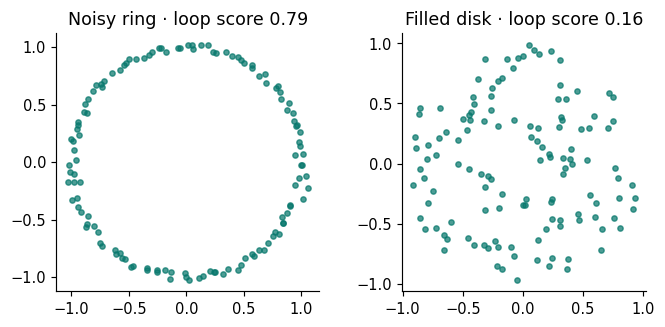

In [2]:
def longest_loop(points):
    if len(points) < 4:
        return 0.0
    pair_distances = pdist(points)
    scale = np.quantile(pair_distances, 0.9)
    if scale <= 1e-8:
        return 0.0
    filtration = squareform(pair_distances / scale)
    intervals = ripser(filtration, distance_matrix=True, maxdim=1)["dgms"][1]
    return float((intervals[:, 1] - intervals[:, 0]).max()) if len(intervals) else 0.0

rng = np.random.default_rng(42)
theta = np.linspace(0, 2 * np.pi, 128, endpoint=False)
direction = np.column_stack([np.cos(theta), np.sin(theta)])
ring = direction + 0.025 * rng.normal(size=direction.shape)
disk = direction * np.sqrt(rng.uniform(size=(len(theta), 1)))

fig, axes = plt.subplots(1, 2, figsize=(6.5, 3.0), layout="constrained")
for ax, title, shape in zip(axes, ["Noisy ring", "Filled disk"], [ring, disk], strict=True):
    ax.scatter(*shape.T, s=13, alpha=0.72, color="#08786d")
    ax.set_title(f"{title} · loop score {longest_loop(shape):.2f}")
    ax.set_aspect("equal")
plt.show()

## Rank real groups while their names are hidden

The matrix product below performs the SAE reconstruction. Each row holds the activations for one sampled token. Its columns contain just the selected group's latents. Try unit normalization and see which groups move in the ranking.

In [3]:
with np.load(data_dir / "blind-groups.npz", allow_pickle=False) as arrays:
    ids = sorted(key.removesuffix("_codes") for key in arrays.files if key.endswith("_codes"))
    clouds = {key: arrays[f"{key}_codes"] @ arrays[f"{key}_decoder"] for key in ids}

raw = {key: longest_loop(points) for key, points in clouds.items()}
unit = {key: longest_loop(points / np.maximum(np.linalg.norm(points, axis=1, keepdims=True), 1e-8))
        for key, points in clouds.items()}
order = sorted(ids, key=lambda key: (-raw[key], key))
unit_rank = {key: i for i, key in enumerate(sorted(ids, key=lambda key: (-unit[key], key)), 1)}
print("ID      raw rank   loop score   unit-vector rank")
for i, key in enumerate(order, 1):
    print(f"{key:4} {i:10d} {raw[key]:12.3f} {unit_rank[key]:16d}")

ID      raw rank   loop score   unit-vector rank
G03           1        0.203                2
G09           2        0.188                4
G04           3        0.178                5
G10           4        0.175                3
G07           5        0.144                8
G02           6        0.140                6
G12           7        0.134               11
G05           8        0.121                9
G11           9        0.118                1
G06          10        0.105               10
G08          11        0.079                7
G01          12        0.017               12


## Reveal the labels and make a held-out plot

A loop score ranks geometry. Names tell us what the geometry might represent. The plot below learns PCA from an unlabeled Pile point cloud, then projects named weekdays from a separate news sample onto those same axes. The day labels enter only when we color the news points.

 1  G03  Candidate associated with -ing
 2  G09  Published months
 3  G04  Comparison group
 4  G10  Comparison group
 5  G07  Candidate associated with legs and feet
 6  G02  Comparison group
 7  G12  Published years
 8  G05  Comparison group
 9  G11  Comparison group
10  G06  Comparison group
11  G08  Published weekdays
12  G01  Comparison group


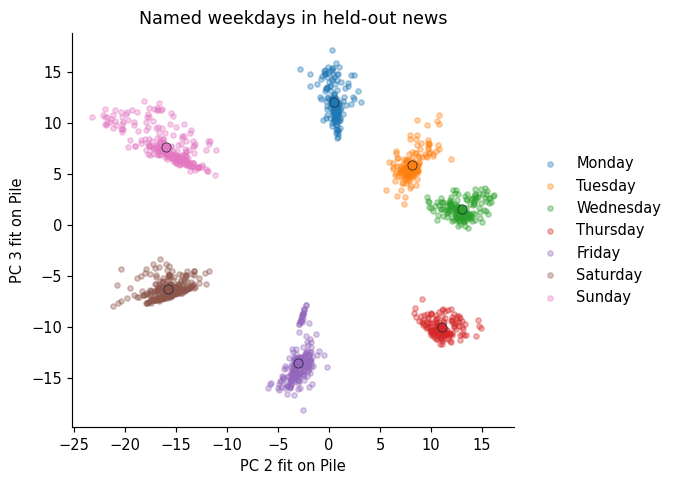

In [4]:
with (data_dir / "group-reveal.csv").open(newline="") as stream:
    names = {row["anonymous_id"]: row["description"] for row in csv.DictReader(stream)}
for i, key in enumerate(order, 1):
    print(f"{i:2d}  {key}  {names[key]}")

with np.load(data_dir / "weekday-reveal.npz", allow_pickle=False) as arrays:
    fit = arrays["fit_cloud"]
    held_out = arrays["news_points"]
    labels = arrays["weekday_id"]
    days = arrays["weekday_names"]
mean = fit.mean(axis=0)
_, _, axes = np.linalg.svd(fit - mean, full_matrices=False)
points = (held_out - mean) @ axes[1:3].T
fig, ax = plt.subplots(figsize=(7.0, 4.5), layout="constrained")
for index, name in enumerate(days):
    xy = points[labels == index]
    color = plt.cm.tab10(index)
    ax.scatter(*xy.T, s=13, color=color, alpha=0.35, label=str(name))
    ax.scatter(*xy.mean(axis=0), s=40, color=color, edgecolor="#162438", linewidth=0.5)
ax.set(xlabel="PC 2 fit on Pile", ylabel="PC 3 fit on Pile", title="Named weekdays in held-out news")
ax.set_aspect("equal")
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.02, 0.5))
plt.show()

**Try it.** Change the ranking cloud to random subsets of 32, 64, or 96 points. Check which ranks move and compare that movement with the separations in the labeled plot. A high-scoring loop is a candidate for inspection, and its rank can change with the text source.

[Full discovery results and data tables](../RESULTS.md#discovery-without-labels)